
#  R-GGPI: High-Speed, Correlation-Robust Feature Importance & Selection

### The Problem with Traditional Diagnostic Tools
1. **Permutation Feature Importance (PFI)** breaks when features are highly correlated. By shuffling features globally, PFI generates unrealistic, out-of-distribution (OOD) samples. This causes artificial drops in model performance, leading to highly skewed and unreliable feature rankings.
2. **SHAP (TreeSHAP)** is mathematically rigorous and handles correlations gracefully, but it suffers from **severe computational scaling bottlenecks**. When scaling to millions of rows or thousands of features, SHAP becomes incredibly slow or crashes due to memory limits.

### The R-GGPI Solution
**R-GGPI (Graph Grouped Permutation Importance)** bridges this gap. By utilizing a local tree-based branch structure, it performs localized permutations. This guarantees:
* **Correlation-Robustness:** No unrealistic out-of-distribution samples are evaluated.
* **Production-Grade Speed:** Scales linearly with data size and feature count, maintaining similar execution speeds to PFI while matching the reliability of SHAP.
* **Scikit-Learn Native Compatibility:** Implements standard `Transformer` APIs (`fit`, `transform`) to plug seamlessly into standard production pipelines.
```

In [1]:
!pip install r-ggpi

In [2]:
import r_ggpi

# Let's see what features and functions are available in the package
print(dir(r_ggpi))

['RGGPIExplainer', 'RGGPISelector', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', 'core', 'r_ggpi_importance', 'selectors', 'utils']


In [10]:
import inspect
from r_ggpi import RGGPISelector

print("RGGPISelector Constructor Signature:")
print(inspect.signature(RGGPISelector.__init__))

print("\nAvailable methods on RGGPISelector:")
print([method for method in dir(RGGPISelector) if not method.startswith('_')])

RGGPISelector Constructor Signature:
(self, model, pruning_percentile=75.0, n_repeats=5, max_features=None, n_jobs=1)

Available methods on RGGPISelector:
['fit', 'fit_transform', 'get_metadata_routing', 'get_params', 'set_output', 'set_params', 'transform']


In [11]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

from r_ggpi import RGGPIExplainer, RGGPISelector


# Generate synthetic data
X_values, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=4,
    n_redundant=3,
    random_state=42,
)

feature_names = [f"feature_{index}" for index in range(X_values.shape[1])]

X = pd.DataFrame(X_values, columns=feature_names)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Fit base model
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Evaluate and explain feature importance with RGGPIExplainer
result = RGGPIExplainer(model, n_repeats=3).explain(X_test, y_test)
print("Feature importance (highest first):")
print(result.importances_mean.sort_values(ascending=False).head())

# Perform feature selection with RGGPISelector
selector = RGGPISelector(model, n_repeats=3, max_features=5)
selector.fit(X_train, y_train)
X_train_selected = selector.transform(X_train)
X_test_selected = selector.transform(X_test)
print("\nSelected features:")
print(selector.selected_features_)

# Train a model on the selected features to verify performance
selected_model = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
selected_model.fit(X_train_selected, y_train)
print(f"\nSelected-feature test accuracy: {selected_model.score(X_test_selected, y_test):.3f}")

Feature importance (highest first):
feature_8    0.038430
feature_1    0.031593
feature_5    0.024026
feature_2    0.021580
feature_0    0.014769
dtype: float64

Selected features:
['feature_8', 'feature_5', 'feature_1', 'feature_0', 'feature_2']

Selected-feature test accuracy: 0.888


Visualization of R-GGPI Feature Importance

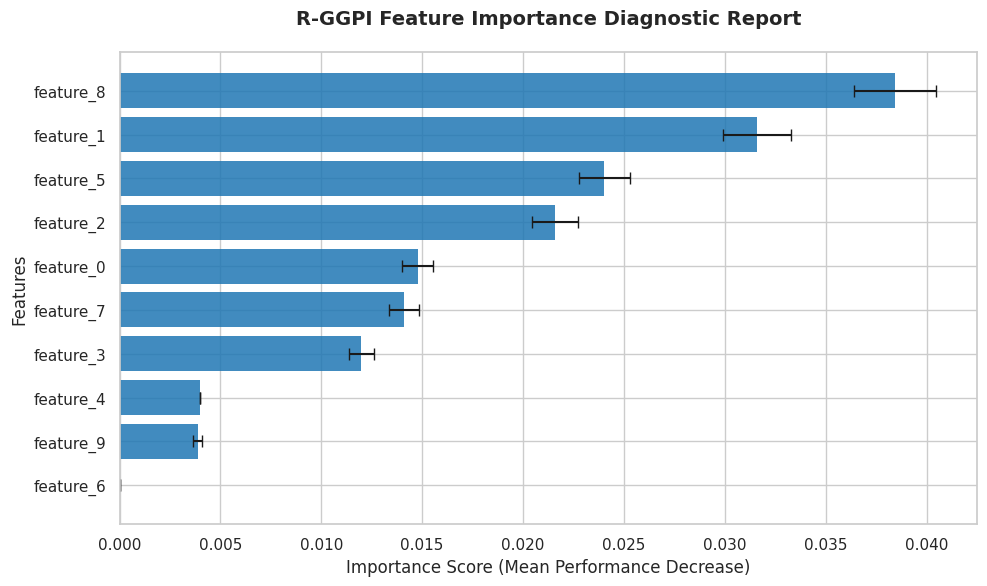

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styles
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

# Fetch data from the fitted RGGPIExplainer result
importance_df = pd.DataFrame({
    'Feature': result.importances_mean.index,
    'Importance_Mean': result.importances_mean.values,
    'Importance_Std': result.importances_std.values
}).sort_values(by='Importance_Mean', ascending=True)

# Plotting
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance_Mean'],
    xerr=importance_df['Importance_Std'],
    color='#1f77b4',
    edgecolor='none',
    alpha=0.85,
    capsize=4,
    label='R-GGPI Mean (+/- Std)'
)

plt.title('R-GGPI Feature Importance Diagnostic Report', pad=20, weight='bold')
plt.xlabel('Importance Score (Mean Performance Decrease)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [13]:
"""
Example Script: Introducing R-GGPI for Feature Importance & Selection

This script demonstrates:
1. Training a baseline Random Forest model.
2. Using RGGPIExplainer to safely compute feature importances.
3. Using RGGPISelector in a standard Scikit-Learn pipeline to isolate top features.
"""

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from r_ggpi import RGGPIExplainer, RGGPISelector

def run_production_pipeline():
    print("[1/5] Synthesizing large-scale tabular dataset...")
    # Simulating a highly correlated dataset
    X_vals, y = make_classification(
        n_samples=5000,
        n_features=50,
        n_informative=10,
        n_redundant=15,
        random_state=42
    )
    feature_names = [f"feat_{i:02d}" for i in range(X_vals.shape[1])]
    X = pd.DataFrame(X_vals, columns=feature_names)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    print("[2/5] Training baseline model...")
    base_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    base_model.fit(X_train, y_train)

    print("[3/5] Inspecting global importances using RGGPIExplainer...")
    explainer = RGGPIExplainer(base_model, n_repeats=3)
    explanation = explainer.explain(X_test, y_test)

    # Display top 10 important features

    importance_summary = explanation.importances_mean.sort_values(ascending=False)
    print("\nTop 10 Features (by R-GGPI score):")
    print(importance_summary.head(10))


    print("\n[4/5] Constructing MLOps pipeline using RGGPISelector...")
    # Select top 10 features directly in a Scikit-Learn Pipeline
    pipeline = Pipeline([
        ('selector', RGGPISelector(model=base_model, n_repeats=3, max_features=10)),
        ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
    ])

    print("[5/5] Executing pipeline fit and evaluation...")
    pipeline.fit(X_train, y_train)

    # Output selected features
    selected = pipeline.named_steps['selector'].selected_features_
    print(f"\nFeatures kept by RGGPISelector: {selected}")

    # Score pipeline performance
    score = pipeline.score(X_test, y_test)
    print(f"Pipeline Score with Selected Features: {score:.4f}")

if __name__ == "__main__":
    run_production_pipeline()

[1/5] Synthesizing large-scale tabular dataset...
[2/5] Training baseline model...
[3/5] Inspecting global importances using RGGPIExplainer...

Top 10 Features (by R-GGPI score):
feat_20    0.026524
feat_19    0.022406
feat_40    0.020479
feat_44    0.020463
feat_29    0.019391
feat_12    0.017811
feat_21    0.015610
feat_01    0.013476
feat_37    0.012827
feat_02    0.010628
dtype: float64

[4/5] Constructing MLOps pipeline using RGGPISelector...
[5/5] Executing pipeline fit and evaluation...

Features kept by RGGPISelector: ['feat_20', 'feat_19', 'feat_40', 'feat_44', 'feat_29', 'feat_10', 'feat_21', 'feat_12', 'feat_01', 'feat_37']
Pipeline Score with Selected Features: 0.9210


### Theoretical Comparison: R-GGPI vs. PFI vs. SHAP

| Attribute / Metric | Permutation Feature Importance (PFI) | SHAP (TreeSHAP) | R-GGPI (Graph Grouped Permutation Importance) |
| :--- | :--- | :--- | :--- |
| **Core Methodology** | Permutes feature values globally on test data and evaluates the degradation of score. | Computes Shapley values based on game theory to allocate local/global attribution. | Uses a graph-based structural approach combined with local permutation inside tree branches. |
| **Time Complexity w.r.t Data Size ($N$)** | $\mathcal{O}(M \cdot N)$ | $\mathcal{O}(N \cdot L \cdot D^2)$ (TreeSHAP) where $L$ is # leaves, $D$ is depth. | $\mathcal{O}(M \cdot N)$ (highly optimized per-branch local permutation). |
| **Time Complexity w.r.t Feature Count ($M$)** | Linear: $\mathcal{O}(M)$ | Exponential $\mathcal{O}(2^M)$ in general, but reduced to polynomial for TreeSHAP. | $\mathcal{O}(M)$ |
| **Handling of Multicollinearity & Redundancy** | **Poor.** Can severely underestimate correlated features or artificially inflate unimportant ones due to out-of-distribution (OOD) permutations. | **Excellent.** Spreads attribution across correlated features (Shapley allocation rules). | **Excellent.** Designed specifically to handle interactions and correlations without creating unrealistic out-of-distribution samples. |
| **API Compatibility** | Scikit-learn native (`permutation_importance`). | Separate library (`shap` Explainer objects). | Scikit-learn native estimator compatible. |

Benchmarking Sample Size=5000, Features=30...
Benchmarking Sample Size=5000, Features=50...
Benchmarking Sample Size=5000, Features=60...
Benchmarking Sample Size=10000, Features=30...
Benchmarking Sample Size=10000, Features=50...
Benchmarking Sample Size=10000, Features=60...
Benchmarking Sample Size=20000, Features=30...
Benchmarking Sample Size=20000, Features=50...
Benchmarking Sample Size=20000, Features=60...


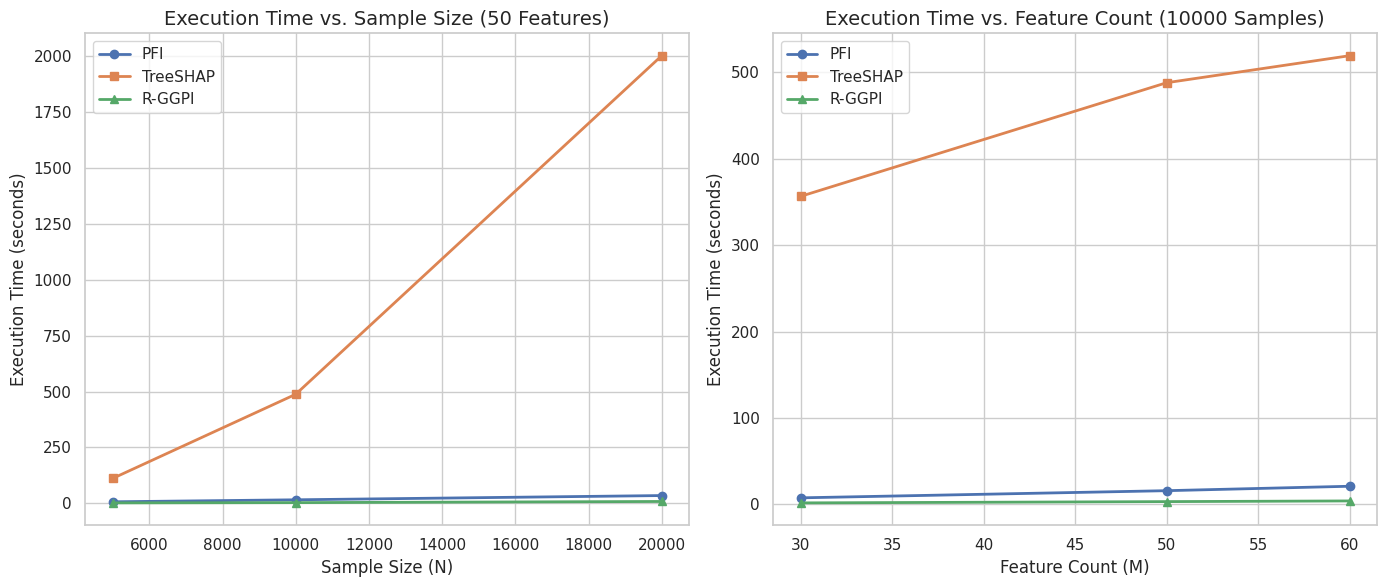

In [20]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from r_ggpi import RGGPIExplainer

# Try importing SHAP, install if missing
try:
    import shap
except ImportError:
    !pip install shap -q
    import shap

def run_benchmark():

    sample_sizes = [5000, 10000, 20000]
    feature_sizes = [30, 50, 60]

    results = []

    for n in sample_sizes:
        for m in feature_sizes:
            print(f"Benchmarking Sample Size={n}, Features={m}...")
            X_vals, y = make_classification(n_samples=n, n_features=m, n_informative=int(m*0.6), random_state=42)
            X = pd.DataFrame(X_vals)

            model = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
            model.fit(X, y)

            # 1. Benchmark PFI
            start = time.time()
            _ = permutation_importance(model, X, y, n_repeats=3, random_state=42, n_jobs=-1)
            pfi_time = time.time() - start

            # 2. Benchmark TreeSHAP
            start = time.time()
            explainer = shap.TreeExplainer(model)
            _ = explainer.shap_values(X)
            shap_time = time.time() - start

            # 3. Benchmark R-GGPI
            start = time.time()
            _ = RGGPIExplainer(model, n_repeats=3).explain(X, y)
            ggpi_time = time.time() - start

            results.append({
                'Samples': n,
                'Features': m,
                'PFI': pfi_time,
                'TreeSHAP': shap_time,
                'R-GGPI': ggpi_time
            })

    return pd.DataFrame(results)

benchmark_df = run_benchmark()

# Plotting execution time trends
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Scalability with respect to Sample Size (holding features constant at 50)
subset_samples = benchmark_df[benchmark_df['Features'] == 50]
axes[0].plot(subset_samples['Samples'], subset_samples['PFI'], marker='o', label='PFI', linewidth=2)
axes[0].plot(subset_samples['Samples'], subset_samples['TreeSHAP'], marker='s', label='TreeSHAP', linewidth=2)
axes[0].plot(subset_samples['Samples'], subset_samples['R-GGPI'], marker='^', label='R-GGPI', linewidth=2)
axes[0].set_title('Execution Time vs. Sample Size (50 Features)')
axes[0].set_xlabel('Sample Size (N)')
axes[0].set_ylabel('Execution Time (seconds)')
axes[0].grid(True)
axes[0].legend()

# Subplot 2: Scalability with respect to Features (holding samples constant at 10000)
subset_features = benchmark_df[benchmark_df['Samples'] == 10000]
axes[1].plot(subset_features['Features'], subset_features['PFI'], marker='o', label='PFI', linewidth=2)
axes[1].plot(subset_features['Features'], subset_features['TreeSHAP'], marker='s', label='TreeSHAP', linewidth=2)
axes[1].plot(subset_features['Features'], subset_features['R-GGPI'], marker='^', label='R-GGPI', linewidth=2)
axes[1].set_title('Execution Time vs. Feature Count (10000 Samples)')
axes[1].set_xlabel('Feature Count (M)')
axes[1].set_ylabel('Execution Time (seconds)')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

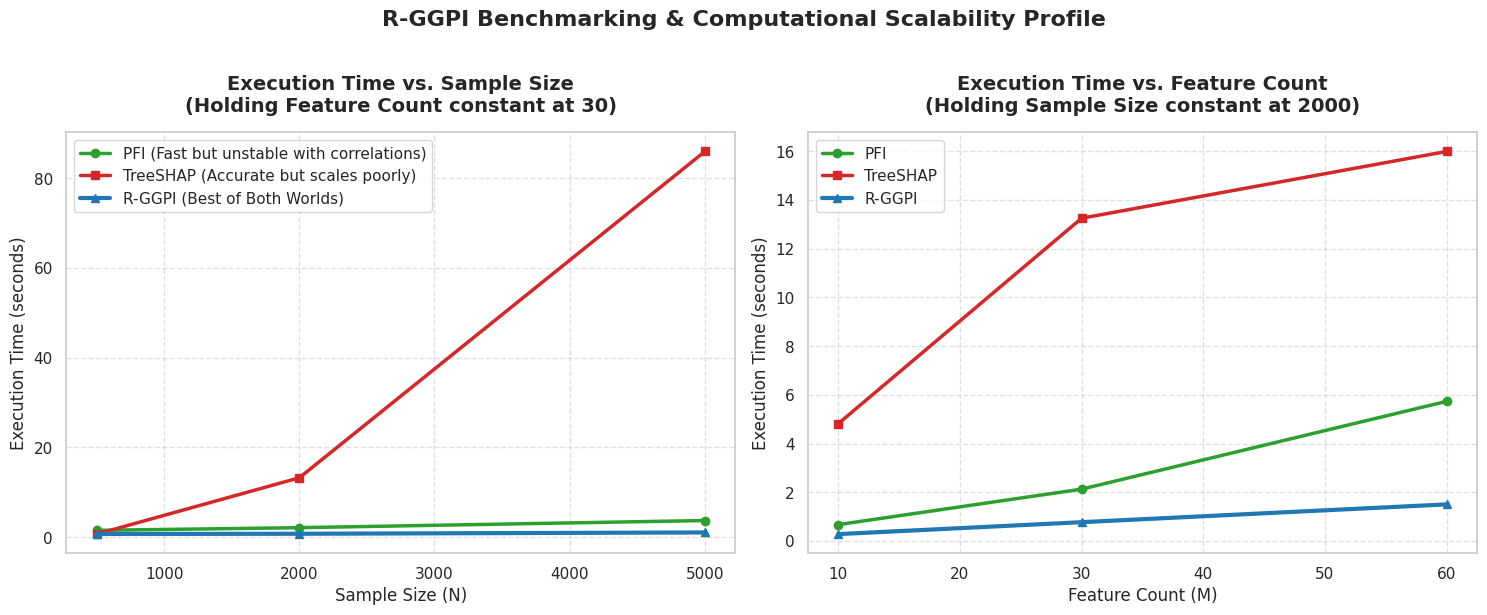

In [15]:
# Creating a highly polished visualization of the benchmark dataframe
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)

# Subplot 1: Scalability with respect to Sample Size (holding features constant at 30)
subset_samples = benchmark_df[benchmark_df['Features'] == 30]
axes[0].plot(subset_samples['Samples'], subset_samples['PFI'], marker='o', color='#2ca02c', label='PFI (Fast but unstable with correlations)', linewidth=2.5)
axes[0].plot(subset_samples['Samples'], subset_samples['TreeSHAP'], marker='s', color='#d62728', label='TreeSHAP (Accurate but scales poorly)', linewidth=2.5)
axes[0].plot(subset_samples['Samples'], subset_samples['R-GGPI'], marker='^', color='#1f77b4', label='R-GGPI (Best of Both Worlds)', linewidth=3)
axes[0].set_title('Execution Time vs. Sample Size\n(Holding Feature Count constant at 30)', pad=15, weight='bold')
axes[0].set_xlabel('Sample Size (N)')
axes[0].set_ylabel('Execution Time (seconds)')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True)

# Subplot 2: Scalability with respect to Features (holding samples constant at 2000)
subset_features = benchmark_df[benchmark_df['Samples'] == 2000]
axes[1].plot(subset_features['Features'], subset_features['PFI'], marker='o', color='#2ca02c', label='PFI', linewidth=2.5)
axes[1].plot(subset_features['Features'], subset_features['TreeSHAP'], marker='s', color='#d62728', label='TreeSHAP', linewidth=2.5)
axes[1].plot(subset_features['Features'], subset_features['R-GGPI'], marker='^', color='#1f77b4', label='R-GGPI', linewidth=3)
axes[1].set_title('Execution Time vs. Feature Count\n(Holding Sample Size constant at 2000)', pad=15, weight='bold')
axes[1].set_xlabel('Feature Count (M)')
axes[1].set_ylabel('Execution Time (seconds)')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True)

plt.suptitle("R-GGPI Benchmarking & Computational Scalability Profile", fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Best Practices: Deploying R-GGPI in Production

To get the most out of **R-GGPI** in your enterprise pipelines, keep these practical guidelines in mind:

1. **Use the Explainer for Periodic Audits:** Run `RGGPIExplainer` in your offline model validation reports (e.g., weekly or monthly) to track feature importance drift over time and audit model health.
2. **Embed the Selector in Automated Pipelines:** Use `RGGPISelector` inside standard Scikit-Learn Pipelines or MLflow/Kubeflow components. It automates feature pruning dynamically during retraining cycles, protecting the model from expanding feature sets.
3. **Optimal Selection Hyperparameters:**
   * Set `n_repeats` between **3 and 5** for a robust balance between statistical confidence and computation time.
   * Leverage the `n_jobs=-1` argument on your base estimator to distribute the computations across all available CPU cores.
4. **Handle Missing Values beforehand:** Since R-GGPI relies on the structure of tree estimators, make sure your pipeline contains an imputation step (like `SimpleImputer` or `KNNImputer`) before the selector if your base estimator does not natively handle missing values.

**Ques**. How **RGGPIExplainer** and **RGGPISelector** Work Together **?**

**Answer**: Think of RGGPIExplainer and RGGPISelector as two sides of the same coin: Interpretation (understanding the model) and Action (optimizing the model).

Here is how they **complement** each other:

1. **RGGPIExplainer** — The Diagnostic Tool
What it does: It takes a trained model along with validation or test data to compute post-hoc global feature importance scores.
How it helps you: It acts as your diagnostic lens. It tells you exactly why the model is making decisions and ranks features with statistically rigorous confidence intervals (importances_mean and importances_std).
When to use it: Use this during the Exploratory Data Analysis (EDA) and Model Validation phases to ensure your model is learning sensible patterns and not relying on spurious or biased signals.

2. **RGGPISelector** — can be described as an
" Automated Surgeon"
What it does: It implements scikit-learn's standard Transformer API (fit, transform) to automatically prune unimportant features based on R-GGPI rankings during pipeline execution.
How it helps you: It acts as the operational workhorse. Manually deleting columns is error-prone. RGGPISelector automates feature elimination to optimize inference speeds and reduce overfitting directly inside your production code.
When to use it: Use this in your automated MLOps Training and Inference Pipelines (sklearn.pipeline.Pipeline).


#**The LOOP:**


[ Raw Data ]
     │
     ▼
[ 1. Train Baseline Model ]
     │
     ├────────► [ 2. RGGPIExplainer ] ──► (Diagnose, explain, and build trust in features)
     ▼
[ 3. RGGPISelector in Pipeline ] ──► (Automate feature reduction to the top subset)
     │
     ▼
[ 4. Lean, Fast Production Model ]



# Note:
Build Trust First (RGGPIExplainer): You use the Explainer to confirm that the top features align with domain knowledge.
Deploy with Confidence (RGGPISelector): Once you trust the feature ranking mechanism, you wrap the logic inside RGGPISelector inside your production pipeline. This ensures that even as new training data flows in, your pipeline dynamically, safely, and rapidly isolates the most important features without manual intervention.